# 定义损失函数：传入参数向量（二元）


In [39]:
import torch
from torch.optim import SGD
import numpy as np
import matplotlib.pyplot as plt
def f(w):
    return 0.05 * w[0]**2 + w[1] ** 2

# 定义函数，实现梯度下降

In [40]:
# 定义函数，实现梯度下降法流程，传入 初始参数、优化器、训练迭代次数
def gradient_descent(w, optimizer, lr_scheduler, n_iters):
    # 用列表保存参数点坐标
    w0_list = []
    w1_list = []
    # 用列表保存学习率变化
    lr_list = []
    for i in range(n_iters):
        w0_list.append(w[0].item())
        w1_list.append(w[1].item())
        lr_list.append(optimizer.param_groups[0]['lr'])
        # 1. 前向传播、计算损失
        loss = f(w)
        # 2. 反向传播
        loss.backward()
        # 3. 更新参数
        optimizer.step()
        # 4. 梯度清零
        optimizer.zero_grad()
        # 5. 更新学习率
        lr_scheduler.step()
    return w0_list, w1_list, lr_list

# # 定义参数

In [41]:
# 定义训练超参数
lr = 0.9
n_iters = 500
# 定义初始参数
w = torch.tensor([-7.0, 2], requires_grad=True)

# 定义优化器和学习率调度器

In [42]:
from torch.optim.lr_scheduler import StepLR

optimizer = SGD([w], lr=lr)
lr_scheduler = StepLR(optimizer, step_size=10, gamma=0.7)
w0_list, w1_list, lr_list = gradient_descent(w, optimizer, lr_scheduler, n_iters)

# 画图

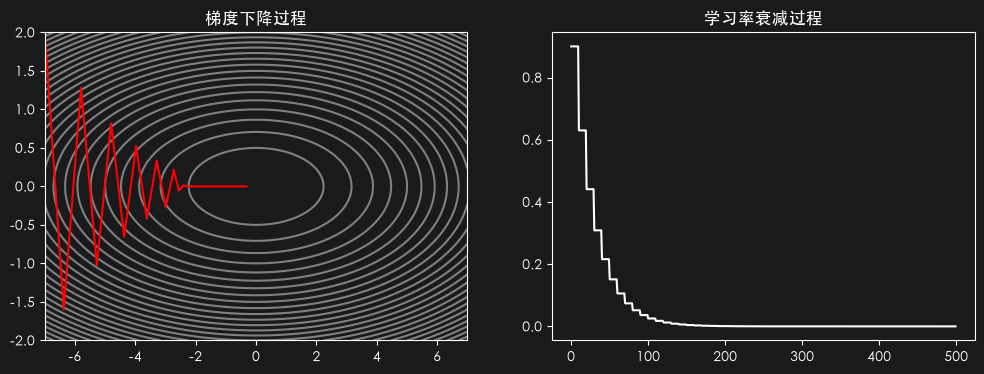

In [43]:
plt.rcParams['font.sans-serif'] = ['STHeiti']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# 等高线
x0, x1 = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
loss = f([x0, x1])
ax[0].contour(x0, x1, loss, colors='gray', levels=30)
ax[0].plot(w0_list, w1_list, color='r')
ax[0].set_title("梯度下降过程")
ax[1].plot(lr_list, color='w')
ax[1].set_title("学习率衰减过程")
plt.show()

# 总结
学习率衰减 (Learning Rate Decay)：在训练过程中动态降低学习率，前期大步探索，后期小步微调，常见策略包括等间隔衰减、指定节点衰减和指数衰减。